## Step 1 — Environment Setup and Global Configurations

In [1]:
# Import operating system and core numerical/tensor libraries
import os, torch, numpy as np
import matplotlib.pyplot as plt
from datasets import load_from_disk
from transformers import (BertTokenizer,
                          BertForSequenceClassification,
                          get_linear_schedule_with_warmup)
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from google.colab import drive

drive.mount('/content/drive')

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CSV_PATH   = "/content/drive/MyDrive/Licenta/IMDB Dataset.csv"
MODEL_NAME = "bert-base-uncased"
BATCH_SIZE = 16
NUM_EPOCHS = 3

print(f"Device: {DEVICE}")

Mounted at /content/drive
Device: cuda


## Step 2 — Data Preprocessing and Tokenization Function

In [2]:
# Import pandas for data manipulation and re for regular expressions
import pandas as pd, re
from sklearn.model_selection import train_test_split

def prepare_data(max_length):
    """Tokenize and split dataset for a given max_length."""
    print(f"\nPreparing data with MAX_LENGTH={max_length}...")

    df = pd.read_csv(CSV_PATH) # Load the CSV file into a pandas DataFrame
    df.columns = ["text", "sentiment"] # Standardize column names
    df["label"] = df["sentiment"].map({"positive": 1, "negative": 0}) # Map string sentiments to binary integer labels
    df["text"] = df["text"].apply(lambda t: re.sub(r"\s+", " ",  # Clean text: remove HTML tags, replace multiple spaces with single space, and strip whitespace
                  re.sub(r"<.*?>", " ", t)).strip())
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True) # Drop duplicated rows based on text content to prevent data leakage

    # Split the full dataset into train/validation (85%) and test (15%) sets
    train_val, test_df = train_test_split(df, test_size=0.15,
                         random_state=42, stratify=df["label"])

    # Split the train_val set further into train (70% of total) and validation (15% of total)
    train_df, val_df   = train_test_split(train_val,
                         test_size=0.15/0.85,
                         random_state=42, stratify=train_val["label"])

    tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

    # Helper function to tokenize text sequences to a specified max_length
    def tokenize(texts):
        return tokenizer(texts, truncation=True,
                         padding="max_length",
                         max_length=max_length,
                         return_tensors="pt")

    # Helper function to create PyTorch DataLoaders from DataFrames
    def make_loader(df, shuffle):
        enc = tokenize(df["text"].tolist()) # Tokenize all text entries in the dataset split
        labels = torch.tensor(df["label"].tolist(), dtype=torch.long) # Convert pandas labels to PyTorch tensors
        ds = TensorDataset(enc["input_ids"], # Group input IDs, attention masks, and labels into a TensorDataset
                           enc["attention_mask"], labels)
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle) # Wrap dataset in a DataLoader for batching and optional shuffling

    # Return DataLoaders for train (shuffled), validation (unshuffled), and test (unshuffled) sets
    return (make_loader(train_df, True),
            make_loader(val_df,   False),
            make_loader(test_df,  False))

## Step 3 — Model Training and Evaluation Logic

In [3]:
# Model Training and Validation Logic
# Trains BERT for NUM_EPOCHS and evaluates ONLY on the VALIDATION set.
# The test set is never touched here — it is reserved for evaluate.ipynb.
# Best model for each MAX_LENGTH is saved to Drive.

import time

def train_and_evaluate(max_length):
    """Fine-tune BERT and evaluate on the validation set only."""
    total_start = time.time()

    # Prepare loaders — test_loader returned but not used here
    train_loader, val_loader, _ = prepare_data(max_length)

    # Load pre-trained BERT for binary classification
    model = BertForSequenceClassification.from_pretrained(
                MODEL_NAME, num_labels=2).to(DEVICE)

    # AdamW optimizer with weight decay
    optimizer   = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    total_steps = len(train_loader) * NUM_EPOCHS
    # Linear warmup over 10% of steps, then linear decay to zero
    scheduler   = get_linear_schedule_with_warmup(
                      optimizer,
                      num_warmup_steps=int(0.1 * total_steps),
                      num_training_steps=total_steps)

    epoch_times  = []
    best_val_acc = 0.0
    best_val_f1  = 0.0

    # Folder where the best model for this MAX_LENGTH will be saved
    save_path = f"/content/drive/MyDrive/Licenta/model_maxlen_{max_length}"
    os.makedirs(save_path, exist_ok=True)

    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()
        model.train()
        total_loss, correct, total = 0, 0, 0

        # Training loop
        for input_ids, attention_mask, labels in train_loader:
            input_ids      = input_ids.to(DEVICE)
            attention_mask = attention_mask.to(DEVICE)
            labels         = labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask,
                            labels=labels)
            outputs.loss.backward()
            # Clip gradients to prevent exploding gradient problem
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

            total_loss += outputs.loss.item()
            preds       = torch.argmax(outputs.logits, dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)

        train_acc  = correct / total
        epoch_time = time.time() - epoch_start
        epoch_times.append(round(epoch_time / 60, 1))  # store in minutes

        # Validation loop — no gradient updates
        model.eval()
        val_preds, val_labels_list = [], []
        with torch.no_grad():
            for input_ids, attention_mask, labels in val_loader:
                out   = model(input_ids=input_ids.to(DEVICE),
                              attention_mask=attention_mask.to(DEVICE))
                preds = torch.argmax(out.logits, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_labels_list.extend(labels.numpy())

        val_acc = accuracy_score(val_labels_list, val_preds)
        val_f1  = f1_score(val_labels_list, val_preds)

        # Save model if it is the best so far for this MAX_LENGTH
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_val_f1  = val_f1
            model.save_pretrained(save_path)
            print(f"  ✅ Best model saved at epoch {epoch+1} -> {save_path}")

        print(f"  Epoch {epoch+1}/{NUM_EPOCHS} | "
              f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | "
              f"Val F1: {val_f1:.4f} | Time: {epoch_time/60:.1f} min")

    total_time = round((time.time() - total_start) / 60, 1)
    print(f"\n  MAX_LENGTH={max_length} -> "
          f"Best Val Acc: {best_val_acc:.4f} | Best Val F1: {best_val_f1:.4f} | "
          f"Total time: {total_time:.1f} min")
    print(f"  Model saved to: {save_path}")

    # Return ONLY validation metrics — test set is NEVER touched here
    return best_val_acc, best_val_f1, total_time, epoch_times


## Step 4 — Execute Training Pipeline for Each Sequence Length



In [ ]:
# Initialize results dictionary before running individual MAX_LENGTH experiments
results = {}
print("Ready. Run each MAX_LENGTH cell below separately.")


Ready. Run each MAX_LENGTH cell below separately.


### 4.1 — MAX_LENGTH = 128


In [ ]:
# ── Train and validate with MAX_LENGTH = 128 ──────────────────────────────
# Run this cell independently. It trains BERT with MAX_LENGTH=128 and
# evaluates on the validation set only. Does NOT touch the test set.

print("=" * 50)
print("Training with MAX_LENGTH = 128")
print("=" * 50)

val_acc_128, val_f1_128, time_128, epoch_times_128 = train_and_evaluate(128)

results[128] = {
    "val_acc":     val_acc_128,
    "val_f1":      val_f1_128,
    "total_time":  time_128,
    "epoch_times": epoch_times_128
}
print(f"MAX_LENGTH=128 done. Val Acc: {val_acc_128:.4f} | Val F1: {val_f1_128:.4f}")


Training with MAX_LENGTH = 128

Preparing data with MAX_LENGTH=128...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 1 -> /content/drive/MyDrive/Licenta/model_maxlen_128
  Epoch 1/3 | Train Acc: 0.8400 | Val Acc: 0.8815 | Val F1: 0.8744 | Time: 15.2 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 2 -> /content/drive/MyDrive/Licenta/model_maxlen_128
  Epoch 2/3 | Train Acc: 0.9282 | Val Acc: 0.8990 | Val F1: 0.9006 | Time: 15.4 min
  Epoch 3/3 | Train Acc: 0.9680 | Val Acc: 0.8982 | Val F1: 0.9002 | Time: 15.4 min

  MAX_LENGTH=128 -> Best Val Acc: 0.8990 | Best Val F1: 0.9006 | Total time: 50.9 min
  Model saved to: /content/drive/MyDrive/Licenta/model_maxlen_128
MAX_LENGTH=128 done. Val Acc: 0.8990 | Val F1: 0.9006


### 4.2 — MAX_LENGTH = 256


In [ ]:
# ── Train and validate with MAX_LENGTH = 256 ──────────────────────────────
# Run this cell independently after MAX_LENGTH=128 finishes.
# Evaluates on the validation set only. Does NOT touch the test set.

print("=" * 50)
print("Training with MAX_LENGTH = 256")
print("=" * 50)

val_acc_256, val_f1_256, time_256, epoch_times_256 = train_and_evaluate(256)

results[256] = {
    "val_acc":     val_acc_256,
    "val_f1":      val_f1_256,
    "total_time":  time_256,
    "epoch_times": epoch_times_256
}
print(f"MAX_LENGTH=256 done. Val Acc: {val_acc_256:.4f} | Val F1: {val_f1_256:.4f}")


Training with MAX_LENGTH = 256

Preparing data with MAX_LENGTH=256...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 1 -> /content/drive/MyDrive/Licenta/model_maxlen_256
  Epoch 1/3 | Train Acc: 0.8771 | Val Acc: 0.9177 | Val F1: 0.9204 | Time: 30.0 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 2 -> /content/drive/MyDrive/Licenta/model_maxlen_256
  Epoch 2/3 | Train Acc: 0.9490 | Val Acc: 0.9232 | Val F1: 0.9219 | Time: 29.9 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 3 -> /content/drive/MyDrive/Licenta/model_maxlen_256
  Epoch 3/3 | Train Acc: 0.9780 | Val Acc: 0.9277 | Val F1: 0.9280 | Time: 30.0 min

  MAX_LENGTH=256 -> Best Val Acc: 0.9277 | Best Val F1: 0.9280 | Total time: 97.4 min
  Model saved to: /content/drive/MyDrive/Licenta/model_maxlen_256
MAX_LENGTH=256 done. Val Acc: 0.9277 | Val F1: 0.9280


### 4.3 — MAX_LENGTH = 512


In [ ]:
# ── Train and validate with MAX_LENGTH = 512 ──────────────────────────────
# Run this cell independently after MAX_LENGTH=256 finishes.
# Evaluates on the validation set only. Does NOT touch the test set.

print("=" * 50)
print("Training with MAX_LENGTH = 512")
print("=" * 50)

val_acc_512, val_f1_512, time_512, epoch_times_512 = train_and_evaluate(512)

results[512] = {
    "val_acc":     val_acc_512,
    "val_f1":      val_f1_512,
    "total_time":  time_512,
    "epoch_times": epoch_times_512
}
print(f"MAX_LENGTH=512 done. Val Acc: {val_acc_512:.4f} | Val F1: {val_f1_512:.4f}")


Training with MAX_LENGTH = 512

Preparing data with MAX_LENGTH=512...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

  ✅ Best model saved at epoch 1 -> /content/drive/MyDrive/Licenta/model_maxlen_512
  Epoch 1/3 | Train Acc: 0.8903 | Val Acc: 0.9373 | Val F1: 0.9383 | Time: 53.8 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 2 -> /content/drive/MyDrive/Licenta/model_maxlen_512
  Epoch 2/3 | Train Acc: 0.9596 | Val Acc: 0.9406 | Val F1: 0.9412 | Time: 53.8 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved at epoch 3 -> /content/drive/MyDrive/Licenta/model_maxlen_512
  Epoch 3/3 | Train Acc: 0.9831 | Val Acc: 0.9426 | Val F1: 0.9433 | Time: 53.8 min

  MAX_LENGTH=512 -> Best Val Acc: 0.9426 | Best Val F1: 0.9433 | Total time: 174.1 min
  Model saved to: /content/drive/MyDrive/Licenta/model_maxlen_512
MAX_LENGTH=512 done. Val Acc: 0.9426 | Val F1: 0.9433


## Step 5 — Select Best Configuration Based on Validation Performance


In [ ]:
results = {
    128: {"val_acc": 0.8990, "val_f1": 0.9006, "total_time": 50.9,  "epoch_times": [15.2, 15.4, 15.4]},
    256: {"val_acc": 0.9277, "val_f1": 0.9280, "total_time": 97.4,  "epoch_times": [30.0, 29.9, 30.0]},
    512: {"val_acc": 0.9426, "val_f1": 0.9433, "total_time": 174.1, "epoch_times": [53.8, 53.8, 53.8]},
}

best_max_length = max(results, key=lambda k: results[k]["val_acc"])
print(f"Best MAX_LENGTH based on validation : {best_max_length}")
print(f"Val Accuracy                        : {results[best_max_length]['val_acc']*100:.2f}%")
print(f"Val F1 Score                        : {results[best_max_length]['val_f1']*100:.2f}%")
print(f"\n-> MAX_LENGTH={best_max_length} selected for final test evaluation in evaluate.ipynb")

Best MAX_LENGTH based on validation : 512
Val Accuracy                        : 94.26%
Val F1 Score                        : 94.33%

-> MAX_LENGTH=512 selected for final test evaluation in evaluate.ipynb


In [ ]:
# Select the best MAX_LENGTH configuration based on VALIDATION accuracy only.
# This choice determines which configuration is used for final test evaluation
# in evaluate.ipynb. The test set is used exactly once, there.

best_max_length = max(results, key=lambda k: results[k]["val_acc"])
print(f"Best MAX_LENGTH based on validation accuracy : {best_max_length}")
print(f"Val Accuracy                                 : {results[best_max_length]['val_acc']*100:.2f}%")
print(f"Val F1 Score                                 : {results[best_max_length]['val_f1']*100:.2f}%")
print(f"\n-> MAX_LENGTH={best_max_length} selected for final test evaluation in evaluate.ipynb")


Best MAX_LENGTH based on validation accuracy : 512
Val Accuracy                                 : 94.26%
Val F1 Score                                 : 94.33%

-> MAX_LENGTH=512 selected for final test evaluation in evaluate.ipynb


## Step 6 - Generate Comparison Tables and Performance Plots

Mounted at /content/drive

   COMPARISON TABLE — MAX_LENGTH IMPACT (evaluated on Validation Set)
 MAX_LENGTH Val Accuracy (%) Val F1 Score (%) Epoch 1 Time Epoch 2 Time Epoch 3 Time Total Train Time Selected
        128           89.90%           90.06%     15.2 min     15.4 min     15.4 min         50.9 min         
        256           92.77%           92.80%     30.0 min     29.9 min     30.0 min         97.4 min         
        512           94.26%           94.33%     53.8 min     53.8 min     53.8 min        174.1 min   ✅ BEST


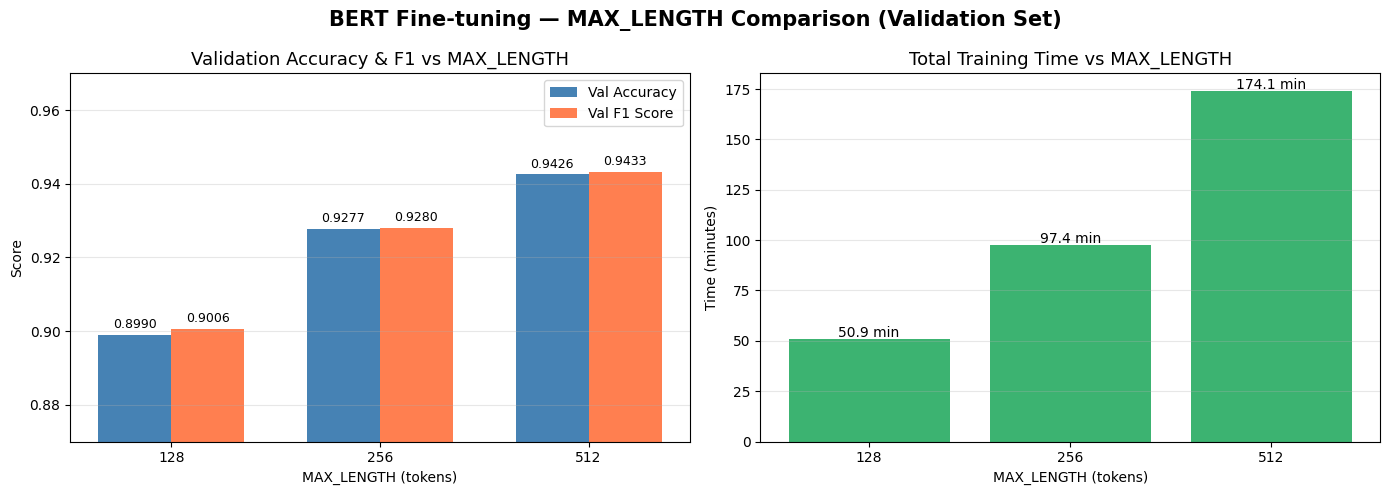

Saved to Drive!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import drive
drive.mount('/content/drive')

# Build comparison table
rows = []
for ml, r in results.items():
    rows.append({
        "MAX_LENGTH":       ml,
        "Val Accuracy (%)": f"{r['val_acc']*100:.2f}%",
        "Val F1 Score (%)": f"{r['val_f1']*100:.2f}%",
        "Epoch 1 Time":     f"{r['epoch_times'][0]:.1f} min",
        "Epoch 2 Time":     f"{r['epoch_times'][1]:.1f} min",
        "Epoch 3 Time":     f"{r['epoch_times'][2]:.1f} min",
        "Total Train Time": f"{r['total_time']:.1f} min",
        "Selected":         "✅ BEST" if ml == best_max_length else ""
    })

df_results = pd.DataFrame(rows)
print("\n" + "="*75)
print("   COMPARISON TABLE — MAX_LENGTH IMPACT (evaluated on Validation Set)")
print("="*75)
print(df_results.to_string(index=False))
print("="*75)

# Save table to Drive
os.makedirs("/content/drive/MyDrive/Licenta", exist_ok=True)
df_results.to_csv("/content/drive/MyDrive/Licenta/comparison_table.csv", index=False)

# Plot
labels = [str(k) for k in results.keys()]
accs   = [v["val_acc"]   for v in results.values()]
f1s    = [v["val_f1"]    for v in results.values()]
times  = [v["total_time"] for v in results.values()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x     = np.arange(len(labels))
width = 0.35
bars1 = axes[0].bar(x - width/2, accs, width, label="Val Accuracy", color="steelblue")
bars2 = axes[0].bar(x + width/2, f1s,  width, label="Val F1 Score", color="coral")
axes[0].set_title("Validation Accuracy & F1 vs MAX_LENGTH", fontsize=13)
axes[0].set_xlabel("MAX_LENGTH (tokens)")
axes[0].set_ylabel("Score")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0.87, 0.97)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
for bar in list(bars1) + list(bars2):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.001,
                 f"{bar.get_height():.4f}",
                 ha="center", va="bottom", fontsize=9)

axes[1].bar(labels, times, color="mediumseagreen")
axes[1].set_title("Total Training Time vs MAX_LENGTH", fontsize=13)
axes[1].set_xlabel("MAX_LENGTH (tokens)")
axes[1].set_ylabel("Time (minutes)")
axes[1].grid(axis="y", alpha=0.3)
for i, t in enumerate(times):
    axes[1].text(i, t + 1, f"{t:.1f} min", ha="center", fontsize=10)

plt.suptitle("BERT Fine-tuning — MAX_LENGTH Comparison (Validation Set)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/comparison_maxlength.png", dpi=150)
plt.show()
print("Saved to Drive!")